# 第 06 关：从风险暴露到风险价格

**本关要回答的问题：** 第 03、05 关问的是"α 是否为零"。本关换一个角度：**每多承担一单位某种风险暴露，平均能多得多少收益？** 这个"每单位暴露对应的补偿"叫**风险价格**，记为 λ（lambda）。

### 两种回归，两个方向
- **时间序列回归**（第 03、05 关）：固定一个资产，沿着时间回归，得到它对各因子的暴露 β。
- **横截面回归**（本关）：固定一个月，在 25 个组合之间回归，看暴露 β 高的组合当月收益是否更高。斜率就是这个月的风险价格。

线性因子模型说：预期超额收益 = 各项暴露 × 对应的风险价格，

$$E[R^e_i]=\lambda_0+\beta_{i}'\lambda .$$

$\beta_i$ 是资产 $i$ 对 $K$ 个因子的暴露组成的向量，$\lambda$ 是 $K$ 个风险价格组成的向量，$\lambda_0$ 是横截面截距。如果模型完全正确，β 全为零的资产只能赚无风险利率，所以 $\lambda_0$ 应该为零。

### Fama–MacBeth 两步法（Fama & MacBeth 1973）
1. **第一步（时间序列）**：在每个月 $t$ 之前，用过去 60 个月的数据估计每个组合的 β。
2. **第二步（横截面）**：在月份 $t$，把 25 个组合的当月超额收益对它们的 β 做回归，得到这个月的风险价格 $\lambda_t$。
3. 把所有月份的 $\lambda_t$ 取时间平均，作为风险价格的估计；用 $\lambda_t$ 的逐月波动计算标准误。

第 3 步是这个方法的巧妙之处：每个月的横截面回归给出 λ 的一个"观测值"，λ 的不确定性可以直接从这些观测值随时间的波动中估计出来，同一个月内各资产收益之间的相关性也就自动考虑进去了。

注意第二步的解释变量是**因子暴露 β**（回归估计出来的敏感度），不是市值、B/M 这样的公司特征。

本关用 25 个规模×B/M 组合和三因子，样本 1963-07 至 2013-12。这是一次方法练习：原论文用的是按 β 排序的股票组合和市场单因子，我们换成了课程已有的组合和因子。

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "course.py").exists()), None)
if ROOT is None:
    raise RuntimeError("请在 asset_pricing_quest 项目或其 notebooks 文件夹中启动 Notebook。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from course import load_returns, style, save_table, paper_note, build_ff5
from analysis import fit_models, model_summary

style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 24)

In [2]:
display(Markdown(paper_note("fama_macbeth")))

**论文对照：** [Fama & MacBeth (1973), Risk, Return, and Equilibrium: Empirical Tests](https://doi.org/10.1086/260061)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 设定样本和时间顺序
样本 1963-07 至 2013-12，共 606 个月；滚动窗口 60 个月。对第二步的每个月 $t$，第一步只用 $t-60,\ldots,t-1$ 月的数据估计 β，保证 β 在月份 $t$ 开始之前就已经知道，不使用"未来信息"。所以第一个能做第二步的月份是 1968-07，第二步一共 606 − 60 = 546 个月。

收益全部用月度小数；被解释变量是组合收益减当月 RF 的超额收益。

In [3]:
START, END, WINDOW = "1963-07", "2013-12", 60
factor_names = ["Mkt-RF", "SMB", "HML"]
ff3 = load_returns("ff3", START, END)
portfolios = load_returns("bm25", START, END)
assert ff3.index.equals(portfolios.index)
y = portfolios.sub(ff3["RF"], axis=0)
f = ff3[factor_names]
assert not y.isna().any().any() and not f.isna().any().any()
display(pd.DataFrame({"起点": [str(y.index[0])], "终点": [str(y.index[-1])],
                      "月份数": [len(y)], "测试组合数": [y.shape[1]], "过去窗口": [WINDOW]}))

,起点,终点,月份数,测试组合数,过去窗口
0,1963-07,2013-12,606,25,60


## 2. 两步估计
**第一步**：对每个组合，在过去 60 个月上做三因子时间序列回归，保留三个斜率 $\hat\beta_{i,t-1}$（下标 $t-1$ 表示只用到 $t-1$ 月为止的信息）。代码用一次矩阵最小二乘同时估计 25 个组合，结果与逐个做 OLS 完全相同。

**第二步**：在月份 $t$，用 25 个组合做横截面回归

$$
R^e_{i,t}=\lambda_{0,t}+\hat{\beta}_{i,t-1}'\lambda_t+u_{i,t},\qquad i=1,\ldots,25.
$$

- $\lambda_t$：三个因子在这个月的风险价格估计，即"暴露每高 1，当月收益高多少"；
- $\lambda_{0,t}$：横截面截距。模型正确时它的平均值应接近零，所以这里保留截距、不强制为零，以便检验；
- $u_{i,t}$：横截面残差。

下面第一张表核对时间顺序（窗口终点总是早于被解释的月份），第二张表是最初三个月的 λ 估计（小数）。

In [4]:
lambda_rows, dates, audit = [], [], []
for t in range(WINDOW, len(y)):
    # 第一步：只用月份 t 之前的 WINDOW 个月，做三因子时间序列回归
    past_f = f.iloc[t-WINDOW:t]
    past_y = y.iloc[t-WINDOW:t]
    x_ts = np.column_stack([np.ones(WINDOW), past_f.to_numpy(dtype=float)])
    coeff, _, rank_ts, _ = np.linalg.lstsq(x_ts, past_y.to_numpy(dtype=float), rcond=None)
    assert rank_ts == x_ts.shape[1]
    betas = coeff[1:].T  # 行：25 个组合；列：3 个因子暴露
    # 第二步：月份 t 的横截面回归，当月超额收益对 [1, β] 回归
    x_cs = np.column_stack([np.ones(len(betas)), betas])
    lambdas, _, rank_cs, _ = np.linalg.lstsq(x_cs, y.iloc[t].to_numpy(dtype=float), rcond=None)
    assert rank_cs == x_cs.shape[1]
    lambda_rows.append(lambdas)
    dates.append(y.index[t])
    audit.append([past_y.index[0], past_y.index[-1], y.index[t]])

risk_prices = pd.DataFrame(lambda_rows, index=pd.PeriodIndex(dates, freq="M"),
                           columns=["Intercept", *factor_names])
information_dates = pd.DataFrame(audit, columns=["窗口起点", "窗口终点", "被解释月份"])
assert (information_dates["窗口终点"] < information_dates["被解释月份"]).all()
display(information_dates.head(3))
display(risk_prices.head(3))
save_table(risk_prices, "06_monthly_risk_prices")

,窗口起点,窗口终点,被解释月份
0,1963-07,1968-06,1968-07
1,1963-08,1968-07,1968-08
2,1963-09,1968-08,1968-09


,Intercept,Mkt-RF,SMB,HML
1968-07,-0.0038,-0.0278,-0.0159,0.0463
1968-08,-0.0067,0.0157,0.0218,0.0163
1968-09,-0.0151,0.0606,0.0165,0.0019


WindowsPath('E:/Eth data/asset_pricing_quest/results/06_monthly_risk_prices.csv')

## 3. 时间平均与不确定性
把 546 个月的 $\lambda_t$ 取平均，就是风险价格的估计。标准误用 $\lambda_t$ 序列本身的波动来算：对每一列做"只有常数项"的回归，常数项就是均值；标准误采用 HAC（Newey–West，6 阶滞后），因为相邻月份的滚动窗口几乎完全重叠，$\lambda_t$ 可能前后相关。

表中各列：`mean_pct_month` 平均风险价格（%/月）；`se_hac_pct` HAC 标准误；`t_hac` t 值；`ci_low_pct`、`ci_high_pct` 95% 置信区间（均值 ± 1.96 × 标准误）；`months` 第二步月份数。图中的横线就是这个区间。

一个技术细节：第一步的 β 是估计出来的，带有误差，这会让第二步的标准误偏小。Shanken（1992）给出了修正公式（Shanken 修正），本关为了简洁没有使用，所以下面的 t 值略偏大。

,mean_pct_month,se_hac_pct,t_hac,ci_low_pct,ci_high_pct,months
term,,,,,,
Intercept,1.0228,0.2686,3.8072,0.4962,1.5493,546
Mkt-RF,-0.5118,0.2530,-2.0234,-1.0076,-0.0160,546
SMB,0.1004,0.1326,0.7573,-0.1594,0.3602,546
HML,0.3660,0.1559,2.3485,0.0605,0.6715,546


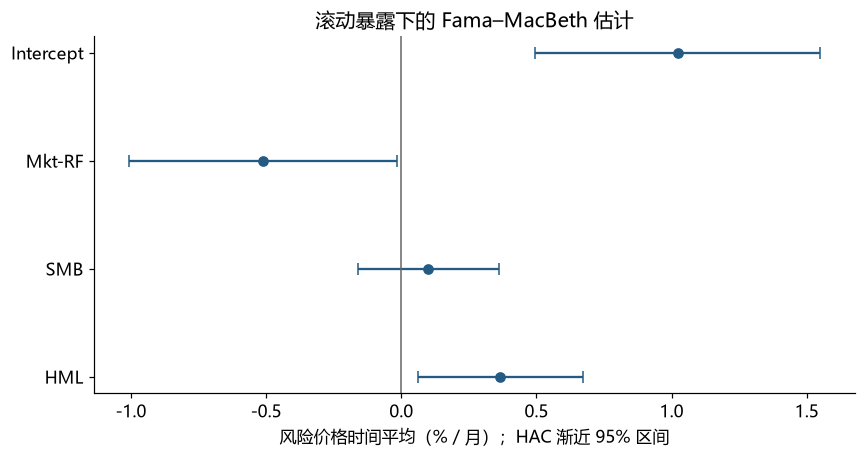

In [5]:
rows = []
for name in risk_prices:
    result = sm.OLS(risk_prices[name].to_numpy(dtype=float), np.ones((len(risk_prices), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6, "use_correction": True})
    mean, se = float(result.params[0]), float(result.bse[0])
    rows.append({"term": name, "mean_pct_month": mean*100, "se_hac_pct": se*100,
                 "t_hac": float(result.tvalues[0]), "ci_low_pct": (mean-1.96*se)*100,
                 "ci_high_pct": (mean+1.96*se)*100, "months": len(risk_prices)})
price_summary = pd.DataFrame(rows).set_index("term")
display(price_summary.round(4))
save_table(price_summary, "06_risk_price_summary")

fig, ax = plt.subplots(figsize=(8, 4.3))
pos = np.arange(len(price_summary))
ax.errorbar(price_summary["mean_pct_month"], pos,
            xerr=1.96*price_summary["se_hac_pct"], fmt="o", color="#245b84", capsize=4)
ax.axvline(0, color="#666666", linewidth=1)
ax.set_yticks(pos, price_summary.index)
ax.set_xlabel("风险价格时间平均（% / 月）；HAC 渐近 95% 区间")
ax.set_title("滚动暴露下的 Fama–MacBeth 估计")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

In [6]:
m = price_summary.loc["Mkt-RF"]
c = price_summary.loc["Intercept"]
display(Markdown(
    f"第二步共 **{len(risk_prices)} 个月**。市场风险价格平均为 **{m['mean_pct_month']:.3f}%/月**"
    f"（95% 区间 [{m['ci_low_pct']:.3f}, {m['ci_high_pct']:.3f}]），横截面截距平均为 **{c['mean_pct_month']:.3f}%/月**。\n\n"
    "**怎样理解负的市场风险价格和很大的截距？** 25 个组合的市场 β 都集中在 1 附近，"
    "而且 β 较高的小盘成长组合恰好平均收益最低。"
    "当所有资产的 β 都接近 1 时，数据只能确定“截距 + 市场风险价格 × 1”这个和，很难把两者分开："
    f"这里两者之和为 {c['mean_pct_month'] + m['mean_pct_month']:.3f}%/月，与市场因子的平均收益相近。"
    "这和第 03 关的发现一致：在规模×B/M 组合上，市场 β 的差异解释不了平均收益的差异。\n\n"
    "λ 的单位是“暴露每高 1，平均每月多得的收益”。例如 HML 的 λ 表示：对 HML 的暴露高 1 的组合，平均每月多赚多少。"))

第二步共 **546 个月**。市场风险价格平均为 **-0.512%/月**（95% 区间 [-1.008, -0.016]），横截面截距平均为 **1.023%/月**。

**怎样理解负的市场风险价格和很大的截距？** 25 个组合的市场 β 都集中在 1 附近，而且 β 较高的小盘成长组合恰好平均收益最低。当所有资产的 β 都接近 1 时，数据只能确定“截距 + 市场风险价格 × 1”这个和，很难把两者分开：这里两者之和为 0.511%/月，与市场因子的平均收益相近。这和第 03 关的发现一致：在规模×B/M 组合上，市场 β 的差异解释不了平均收益的差异。

λ 的单位是“暴露每高 1，平均每月多得的收益”。例如 HML 的 λ 表示：对 HML 的暴露高 1 的组合，平均每月多赚多少。

## 4. 风险价格与因子平均收益的对照
Mkt-RF、SMB、HML 本身都是**可交易组合的收益**。对这类因子，理论给出一个检验：因子组合对自己的暴露是 1、对其他因子的暴露是 0，所以模型如果正确，它的风险价格必须等于它自己的平均收益，即 $\lambda_k=E[f_k]$。横截面估计的 λ 与因子均值相差很大，说明模型在这批资产上的定价不一致。

下表把两者放在一起：`FMB_mean_pct_month` 是 Fama–MacBeth 风险价格，`factor_mean_same_months_pct` 是同样 546 个月里因子的平均收益，单位都是 %/月。

In [7]:
comparison = pd.DataFrame({
    "FMB_mean_pct_month": price_summary.loc[factor_names, "mean_pct_month"],
    "factor_mean_same_months_pct": f.loc[risk_prices.index].mean()*100,
})
display(comparison.round(4))
save_table(comparison, "06_price_vs_factor_mean")

,FMB_mean_pct_month,factor_mean_same_months_pct
Mkt-RF,-0.5118,0.4802
SMB,0.1004,0.1397
HML,0.3660,0.3910


WindowsPath('E:/Eth data/asset_pricing_quest/results/06_price_vs_factor_mean.csv')

**怎么读：** SMB、HML 的风险价格（约 0.10、0.37）与因子均值（约 0.14、0.39）相当接近：在这批组合上，规模和价值暴露获得的补偿与因子本身的收益一致。市场则完全不同：风险价格为负，因子均值为正。原因见上一节，市场 β 在这 25 个组合之间几乎没有差异，横截面回归无法准确估计它的价格。

## 通关证据与 Boss 作答区

提交：时间顺序核对表、风险价格估计表，以及你对截距和三个风险价格的解释。

**Boss：** 如果第一步中某个组合的 β 估计得非常精确，第二步的风险价格估计会因此更可靠吗？请设计一个检查。先写下你的预判，再把 `WINDOW` 从 60 改成 120 运行，观察第二步的月份数和置信区间的宽度如何变化。

**你的回答：**

（留空，运行与思考后填写。）